# Equivalent-depth distributions from individual WK segments

**Question:** Within 10–80 m, do Kelvin and n=1 ER waves allocate excess OLR
power similarly, and how do the CMIP6 distributions compare with NOAA?

Daily 1990–2010 data are split into exact 96-sample windows with 60-day overlap.
We average latitude-by-latitude spectral powers over 15°S–15°N after symmetry
projection. A fixed, dataset-specific smoothed S/A background is subtracted
from each segment. The five existing wave boxes are subdivided by resting-state
dispersion curves into 5 m depth bands. Fractional frequency-cell overlap
allocates cell power; it does not add spectral resolution. Full details and
reproduction commands are in [the workflow README](../scripts/codex_segment_heff/README.md).

For band weights $w_b$ and dataset background $B$, we retain both
$E_{s,b}=2\sum w_b(P_s-B)$ and
$E^+_{s,b}=2\sum w_b\max(P_s-B,0)$, in W² m⁻⁴.
The factor two includes real-field conjugates; exact daily Nyquist is excluded.


In [1]:
import json
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display
from src.paths import DATA_DIR

ROOT = DATA_DIR / "wave_significance/codex_segment_heff"
WAVES = ["Kelvin", "n1ERW", "MRG", "n0EIG", "n1WIG"]
LABELS = {"Kelvin": "Kelvin", "n1ERW": "n=1 ER", "MRG": "MRG", "n0EIG": "n=0 EIG", "n1WIG": "n=1 WIG"}
EXPERIMENTS = {"historical": "Historical", "amip": "AMIP"}
COLORS = {"historical": "C0", "amip": "C1"}
COARSE_EDGES = np.array([10., 30., 50., 80.])
KEYS = ["model", "experiment", "member", "wave"]

audit = json.loads((ROOT / "audit.json").read_text())
assert audit["experiment_counts"] == {"historical": 34, "amip": 25, "observations": 1}
summary = pd.read_csv(ROOT / "depth_summary.csv.gz")
segments = pd.read_csv(ROOT / "segment_summary.csv.gz")
with xr.open_dataset(ROOT / "NOAA_OLR.observations.not_applicable.nc") as source:
    noaa = source.load()
assert len(summary) == 60 * 5 * 14
for name in ["positive_excess_fraction", "mean_spectrum_excess_fraction"]:
    np.testing.assert_allclose(summary.groupby(KEYS)[name].sum(), 1, atol=1e-9)
display(pd.DataFrame(audit["records"]).groupby(["experiment", "calendar"]).agg(
    records=("model", "size"), segments_per_record=("n_segments", lambda v: sorted(set(v)))))


records segments_per_record
experiment   calendar                                        
amip         360_day                    2               [208]
             noleap                    11               [211]
             proleptic_gregorian        7               [211]
             standard                   5               [211]
historical   360_day                    4               [208]
             noleap                    15               [211]
             proleptic_gregorian        9               [211]
             standard                   6               [211]
observations proleptic_gregorian        1               [211]

## Historical and AMIP: all wave types

Each panel compares the five wave families within one experiment. Each model's
mean positive segment excess is normalized over **10–80 m** before forming an
**equally weighted model mean** (34 Historical or 25 AMIP models). Curves are
power-weighted densities in **5 m bins**, each integrating to one; absolute wave
strength is shown separately below. The same axes and wave colors are used in
both panels. Fine differences remain limited by the family-dependent spectral
resolution, especially for ER.


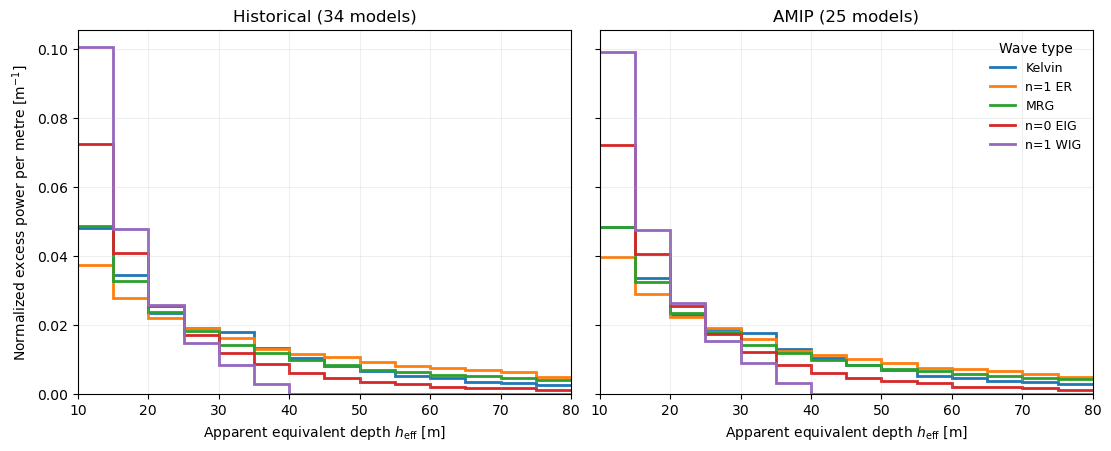

In [2]:
# Normalize each model first, then average models equally within an experiment.
depth_edges_m = np.arange(10., 80.1, 5.)
bin_widths_m = np.diff(depth_edges_m)
fig_wave_comparison, axes_wave_comparison = plt.subplots(
    1, 2, figsize=(11, 4.4), sharex=True, sharey=True, constrained_layout=True,
)

for ax, (experiment, title) in zip(axes_wave_comparison, EXPERIMENTS.items()):
    experiment_rows = summary.loc[summary.experiment.eq(experiment)]
    for i, wave in enumerate(WAVES):
        wave_rows = experiment_rows.loc[experiment_rows.wave.eq(wave)]
        model_fractions = wave_rows.pivot(
            index=["model", "member"], columns="depth_m",
            values="positive_excess_fraction",
        )
        mean_density = model_fractions.mean(axis=0).to_numpy() / bin_widths_m
        ax.stairs(
            mean_density, depth_edges_m, baseline=None,
            color=f"C{i}", linewidth=2, label=LABELS[wave],
        )
    n_models = experiment_rows.model.nunique()
    ax.set(
        title=f"{title} ({n_models} models)",
        xlim=(10, 80), ylim=(0, None),
        xlabel=r"Apparent equivalent depth $h_{\mathrm{eff}}$ [m]",
    )
    ax.grid(alpha=.2)

axes_wave_comparison[0].set_ylabel(r"Normalized excess power per metre [m$^{-1}$]")
axes_wave_comparison[1].legend(title="Wave type", frameon=False, fontsize=9)
plt.show()


## Broad Kelvin–ER comparison

The solid profiles use each record's **mean positive segment excess**, normalized
over its 10–80 m range. Broad groups are 10–30, 30–50 and 50–80 m. Divide by their
unequal widths to show a density. Each model is normalized independently before
the equally weighted model mean is formed; faint lines show individual models.
These are distributions of spectral power, not counts of wave events.

ER depth resolution is substantially poorer than Kelvin resolution. Even these
broad groups can share the response of a single Fourier cell. Similar shapes
would not establish equivalent intrinsic depths or statistical equivalence.


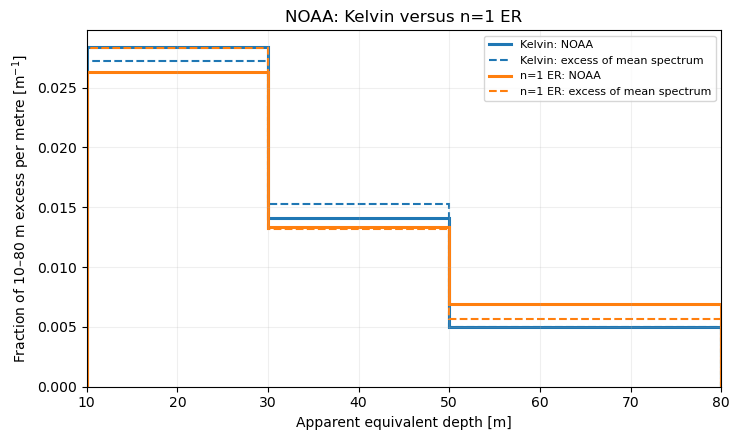

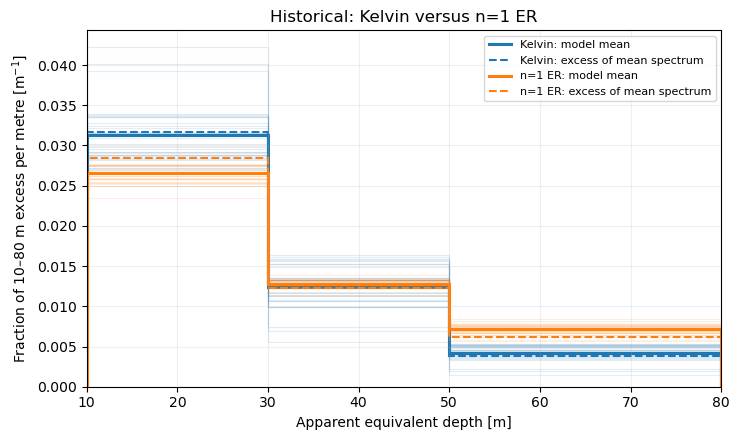

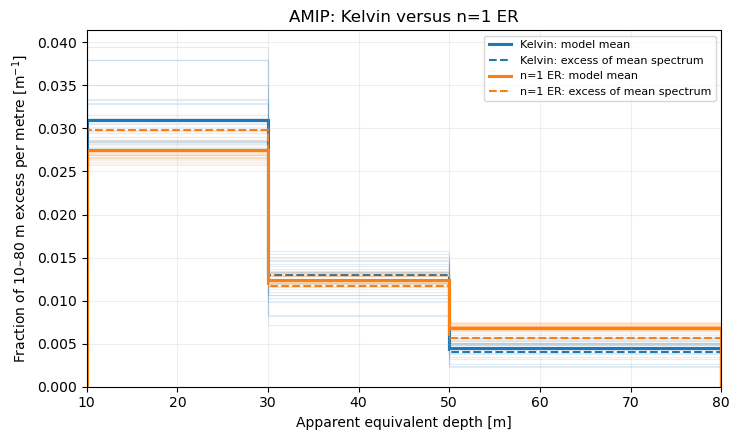

In [3]:
coarse = summary.copy()
coarse["band"] = pd.cut(coarse.lower_m, COARSE_EDGES, right=False, labels=False)
coarse = coarse.groupby(KEYS + ["band"], as_index=False)[[
    "mean_positive_excess", "mean_signed_excess", "background_power",
    "mean_spectrum_positive_excess"]].sum()
coarse["width_m"] = np.diff(COARSE_EDGES)[coarse.band.to_numpy()]
for metric, name in [("mean_positive_excess", "segment_density"),
                     ("mean_spectrum_positive_excess", "pooled_density")]:
    total = coarse.groupby(KEYS)[metric].transform("sum")
    coarse[name] = coarse[metric] / total.where(total > 0) / coarse.width_m

for experiment, title in [("observations", "NOAA"), *EXPERIMENTS.items()]:
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    for wave, color in [("Kelvin", "C0"), ("n1ERW", "C1")]:
        part = coarse.loc[coarse.experiment.eq(experiment) & coarse.wave.eq(wave)]
        matrix = part.pivot(index=["model", "member"], columns="band", values="segment_density")
        for values in matrix.to_numpy():
            if experiment != "observations":
                ax.stairs(values, COARSE_EDGES, color=color, alpha=.13, linewidth=.8)
        ax.stairs(matrix.mean(axis=0), COARSE_EDGES, color=color, linewidth=2.2,
                  label=f"{LABELS[wave]}: " + ("NOAA" if experiment == "observations" else "model mean"))
        pooled = part.groupby("band").pooled_density.mean()
        ax.stairs(pooled, COARSE_EDGES, color=color, linewidth=1.5, linestyle="--",
                  label=f"{LABELS[wave]}: excess of mean spectrum")
    ax.set(xlim=(10, 80), ylim=(0, None), xlabel="Apparent equivalent depth [m]",
           ylabel="Fraction of 10–80 m excess per metre [m$^{-1}$]",
           title=f"{title}: Kelvin versus n=1 ER")
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)
    fig.tight_layout()
    plt.show()


## Absolute strength and broad-band shares

Positive clipping creates excess from noise. The dashed profiles above rectify
the full-record mean spectrum *after averaging*, reducing that contribution.
Signed excess remains the diagnostic for whether mean power exceeds the fitted
background. A negative signed contribution means a deficit relative to that
background, not negative variance. Neither operation is a significance test.


In [4]:
totals = summary.groupby(KEYS, as_index=False)[[
    "mean_observed_power", "background_power", "mean_signed_excess",
    "mean_positive_excess", "mean_spectrum_positive_excess"]].sum()
coarse["segment_fraction"] = coarse.segment_density * coarse.width_m
coarse["pooled_fraction"] = coarse.pooled_density * coarse.width_m
wide = coarse.pivot(index=KEYS, columns="band", values="segment_fraction")
wide.columns = ["share_10_30m", "share_30_50m", "share_50_80m"]
comparison = totals.merge(wide.reset_index(), on=KEYS)
display(comparison.loc[comparison.experiment.eq("observations")].round(4))
display(comparison.loc[~comparison.experiment.eq("observations")].groupby(["experiment", "wave"])[[
    "mean_signed_excess", "mean_positive_excess", "mean_spectrum_positive_excess",
    "share_10_30m", "share_30_50m", "share_50_80m"]].median().round(4))


,model,experiment,member,wave,mean_observed_power,background_power,mean_signed_excess,mean_positive_excess,mean_spectrum_positive_excess,share_10_30m,share_30_50m,share_50_80m
275,NOAA_OLR,observations,not_applicable,Kelvin,39.9914,27.7420,12.2494,16.8631,12.3082,0.5673,0.2819,0.1508
276,NOAA_OLR,observations,not_applicable,MRG,12.8456,11.9551,0.8905,3.7405,1.1490,0.5824,0.2582,0.1594
277,NOAA_OLR,observations,not_applicable,n0EIG,11.0479,10.3521,0.6957,3.0367,1.0831,0.7696,0.1861,0.0444
278,NOAA_OLR,observations,not_applicable,n1ERW,41.2753,31.2065,10.0689,15.6894,10.1342,0.5258,0.2672,0.2070
279,NOAA_OLR,observations,not_applicable,n1WIG,6.9054,6.1037,0.8017,1.7856,0.8120,0.9534,0.0466,0.0000


mean_signed_excess  mean_positive_excess  \
experiment wave                                               
amip       Kelvin              3.5361                8.3801   
           MRG                -0.5257                2.9537   
           n0EIG              -0.4535                1.0632   
           n1ERW              13.4623               21.2769   
           n1WIG               0.1060                0.8214   
historical Kelvin              5.4456               10.3621   
           MRG                -0.4975                3.0525   
           n0EIG              -0.3881                1.1788   
           n1ERW              12.5947               20.6259   
           n1WIG               0.0785                0.8931   

                   mean_spectrum_positive_excess  share_10_30m  share_30_50m  \
experiment wave                                                                
amip       Kelvin                         3.5849        0.5969        0.2601   
           MRG                            0.1869        0.6085        0.2216   
           n0EIG                          0.0153        0.7819        0.1510   
           n1ERW                         13.4859        0.5444        0.2482   
           n1WIG                          0.1417        0.9411        0.0589   
historical Kelvin                         5.4792        0.6235        0.2519   
           MRG                            0.1857        0.6141        0.2194   
           n0EIG                          0.0259        0.7816        0.1502   
           n1ERW                         12.6500        0.5302        0.2554   
           n1WIG                          0.1331        0.9438        0.0562   

                   share_50_80m  
experiment wave                  
amip       Kelvin        0.1392  
           MRG           0.1677  
           n0EIG         0.0673  
           n1ERW         0.2058  
           n1WIG         0.0000  
historical Kelvin        0.1297  
           MRG           0.1662  
           n0EIG         0.0660  
           n1ERW         0.2160  
           n1WIG         0.0000

## Each wave: models versus observations

The 5 m integration grid displays more detail than ER can independently resolve.
Faint curves are individual models; bold colored curves are means of the
individually normalized model distributions. Black is NOAA. The normalization
is conditional on each wave's box and 10–80 m range; absolute strength is shown
separately below.


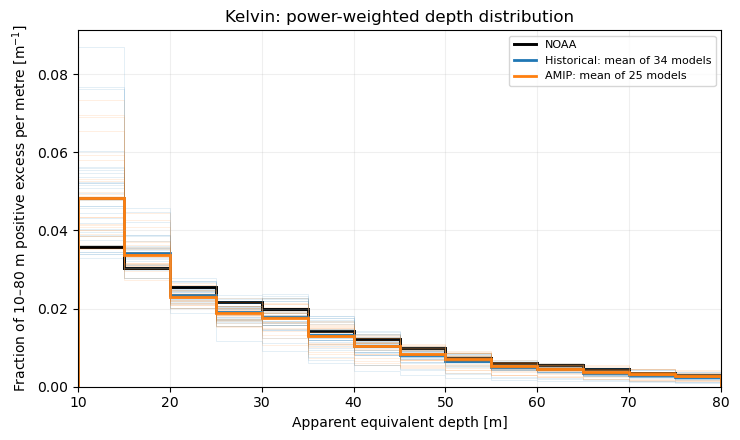

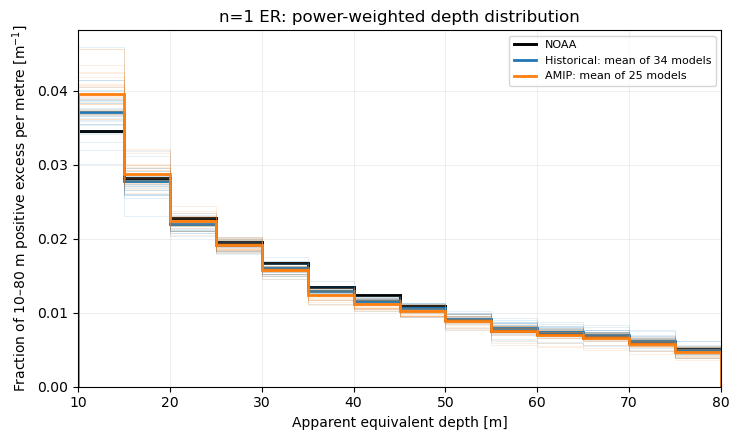

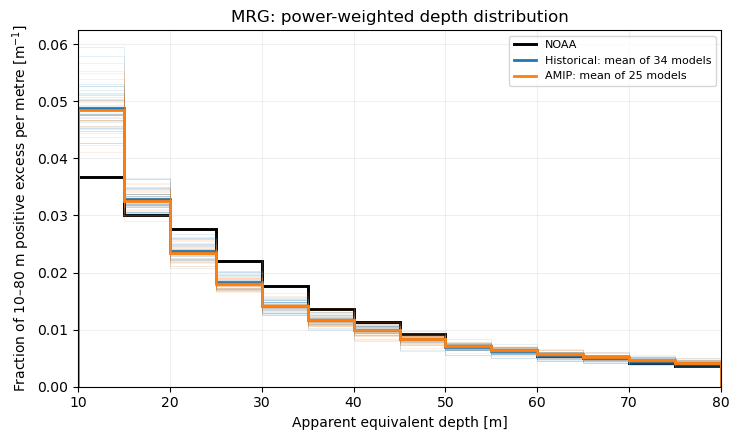

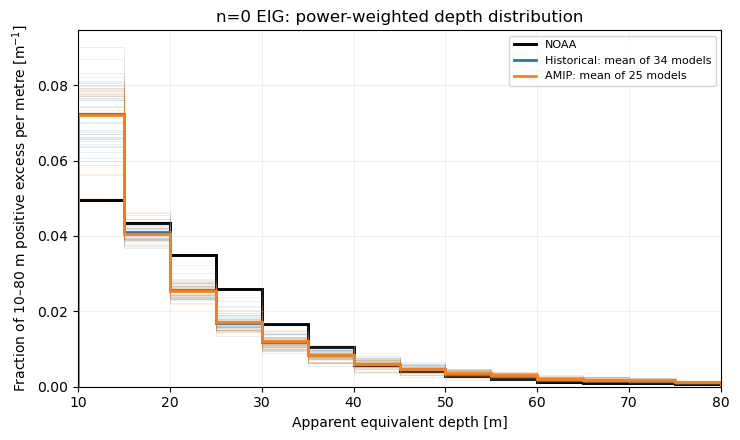

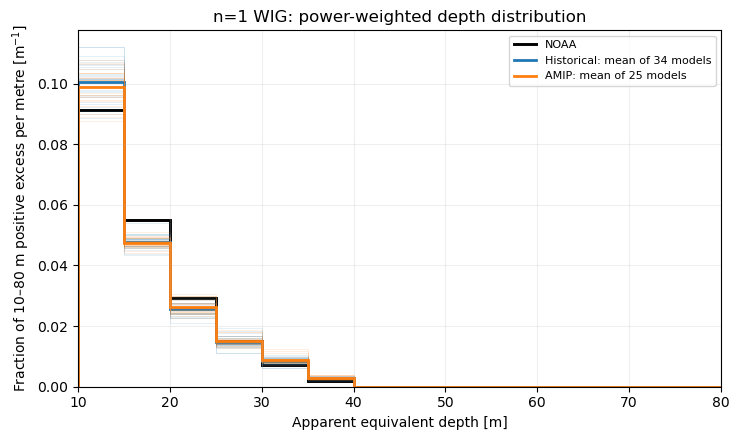

In [5]:
for wave in WAVES:
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    part = summary.loc[summary.wave.eq(wave)].sort_values("depth_m")
    obs = part.loc[part.experiment.eq("observations")]
    ax.stairs(obs.positive_excess_fraction / 5, np.arange(10, 81, 5), color="k", linewidth=2.1, label="NOAA")
    for experiment, title in EXPERIMENTS.items():
        matrix = part.loc[part.experiment.eq(experiment)].pivot(
            index=["model", "member"], columns="depth_m", values="positive_excess_fraction") / 5
        for values in matrix.to_numpy():
            ax.stairs(values, np.arange(10, 81, 5), color=COLORS[experiment], linewidth=.7, alpha=.12)
        ax.stairs(matrix.mean(axis=0), np.arange(10, 81, 5), color=COLORS[experiment], linewidth=2,
                  label=f"{title}: mean of {len(matrix)} models")
    ax.set(xlim=(10, 80), ylim=(0, None), xlabel="Apparent equivalent depth [m]",
           ylabel="Fraction of 10–80 m positive excess per metre [m$^{-1}$]",
           title=LABELS[wave] + ": power-weighted depth distribution")
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)
    fig.tight_layout()
    plt.show()


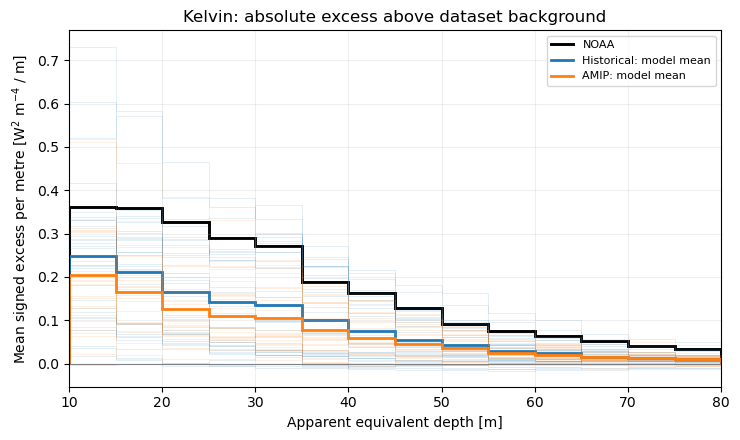

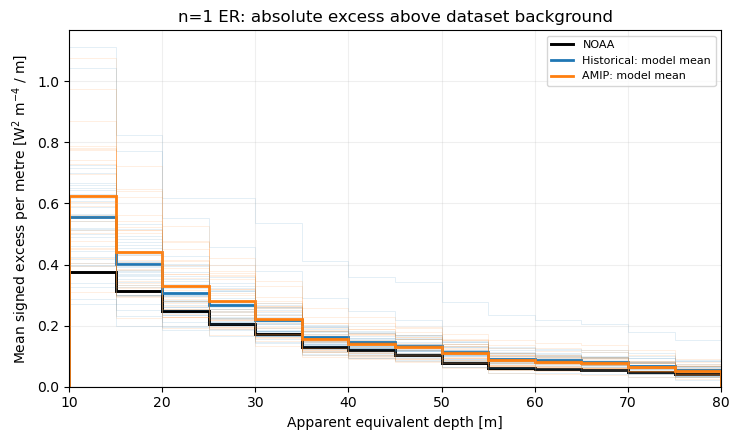

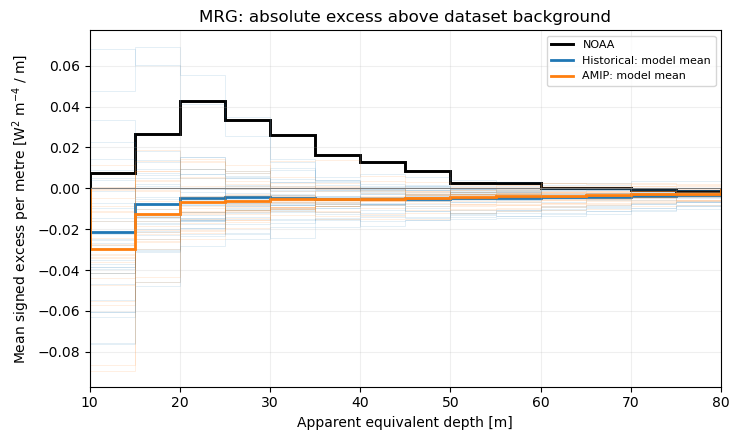

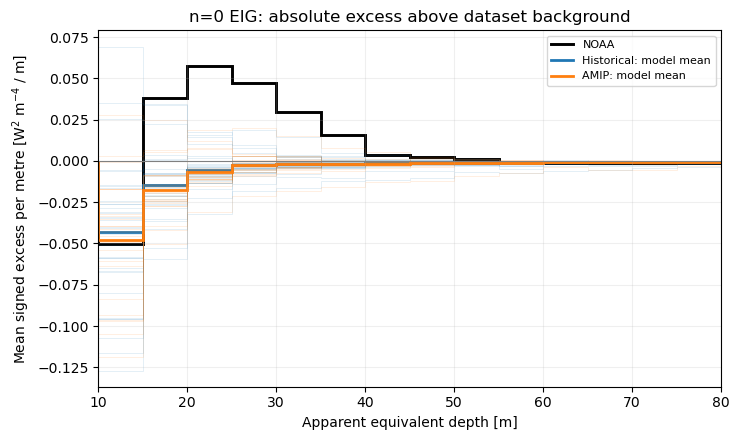

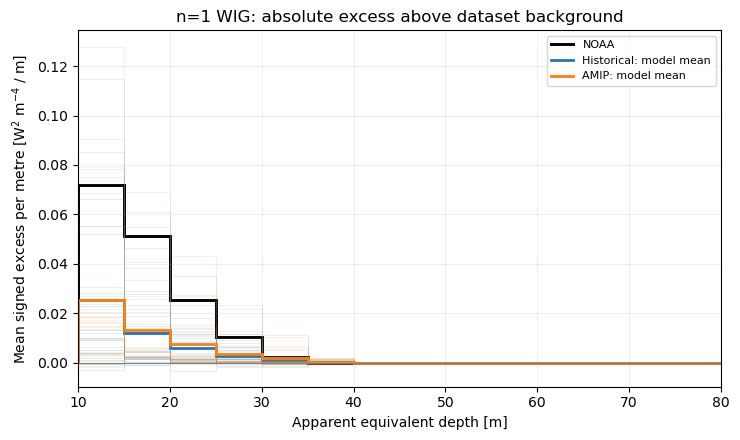

In [6]:
for wave in WAVES:
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    part = summary.loc[summary.wave.eq(wave)].sort_values("depth_m")
    obs = part.loc[part.experiment.eq("observations")]
    ax.stairs(obs.mean_signed_excess / 5, np.arange(10, 81, 5), color="k", linewidth=2.1, label="NOAA")
    for experiment, title in EXPERIMENTS.items():
        matrix = part.loc[part.experiment.eq(experiment)].pivot(
            index=["model", "member"], columns="depth_m", values="mean_signed_excess") / 5
        for values in matrix.to_numpy():
            ax.stairs(values, np.arange(10, 81, 5), color=COLORS[experiment], linewidth=.7, alpha=.12)
        ax.stairs(matrix.mean(axis=0), np.arange(10, 81, 5), color=COLORS[experiment], linewidth=2,
                  label=f"{title}: model mean")
    ax.axhline(0, color=".5", linewidth=.8)
    ax.set(xlim=(10, 80), xlabel="Apparent equivalent depth [m]",
           ylabel="Mean signed excess per metre [W$^2$ m$^{-4}$ / m]",
           title=LABELS[wave] + ": absolute excess above dataset background")
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)
    fig.tight_layout()
    plt.show()


## Spectral resolution and available band area

The depth scale below is $\Delta f/(\Delta f_{m curve}/\Delta h)$, with
$\Delta f=1/96$ cycles/day, summarized over the integer K values whose depth
curves lie inside the wave box. It is a geometric resolving scale, **not a
confidence interval**; taper leakage can broaden the response further. The
second figure counts fractional frequency cells allocated to each depth band.
Differences in curve spacing and box truncation affect band mass, especially
when comparing different wave families. All datasets use the same weights.

A pure-wave control with the same true depth (25 m) and |K|=5 gives different
apparent maximum-mass bands: 22.5 m for Kelvin and 27.5 m for ER, with binned
interquartile widths of 5 and 10 m. The control is reproduced by the workflow
tests. It shows why a small peak/width difference alone does not demonstrate
a physical depth difference; it is not a calibrated uncertainty for these data.


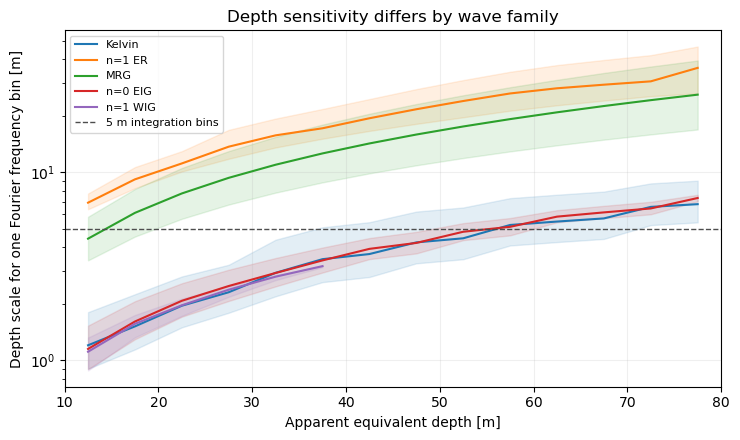

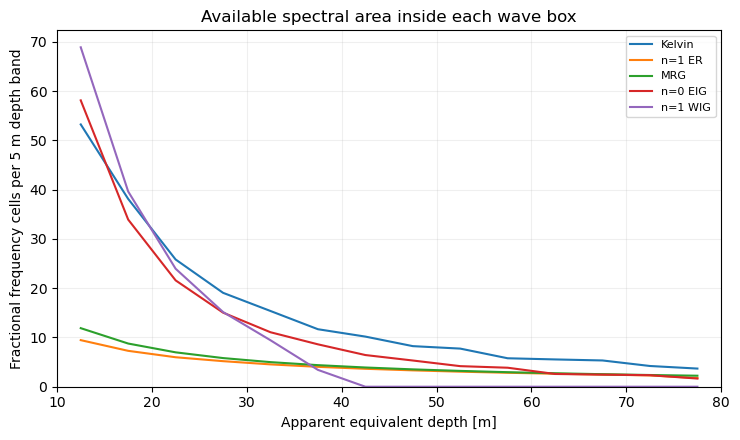

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for i, wave in enumerate(WAVES):
    scales = noaa.one_frequency_bin_depth_scale.sel(wave=wave).dropna("depth", how="all")
    ax.plot(scales.depth, scales.median("zonal_wavenumber", skipna=True), color=f"C{i}", label=LABELS[wave])
    quantiles = scales.quantile([.25, .75], dim="zonal_wavenumber", skipna=True)
    ax.fill_between(scales.depth, quantiles.isel(quantile=0), quantiles.isel(quantile=1), color=f"C{i}", alpha=.12)
ax.axhline(5, color=".3", linestyle="--", linewidth=1, label="5 m integration bins")
ax.set(xlim=(10, 80), yscale="log", xlabel="Apparent equivalent depth [m]",
       ylabel="Depth scale for one Fourier frequency bin [m]", title="Depth sensitivity differs by wave family")
ax.legend(fontsize=8)
ax.grid(alpha=.2)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for i, wave in enumerate(WAVES):
    ax.plot(noaa.depth, noaa.effective_frequency_cells.sel(wave=wave), color=f"C{i}", label=LABELS[wave])
ax.set(xlim=(10, 80), ylim=(0, None), xlabel="Apparent equivalent depth [m]",
       ylabel="Fractional frequency cells per 5 m depth band", title="Available spectral area inside each wave box")
ax.legend(fontsize=8)
ax.grid(alpha=.2)
fig.tight_layout()
plt.show()


## Segment variability in NOAA

Each column is one overlapping 96-day segment. The color is signed excess per
metre, preserving deficits and intermittent enhancements. The 5 m rows inherit
the fractional-cell assumption; adjacent ER rows can largely reflect the same
Fourier cell. Overlap in time also makes neighboring columns dependent.


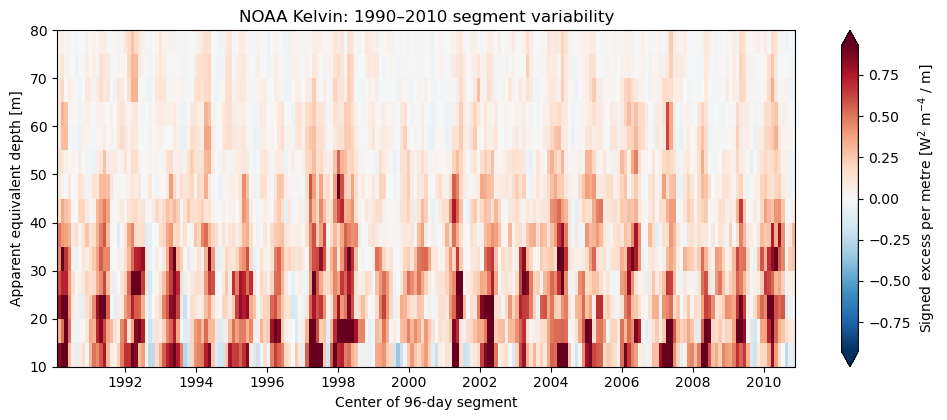

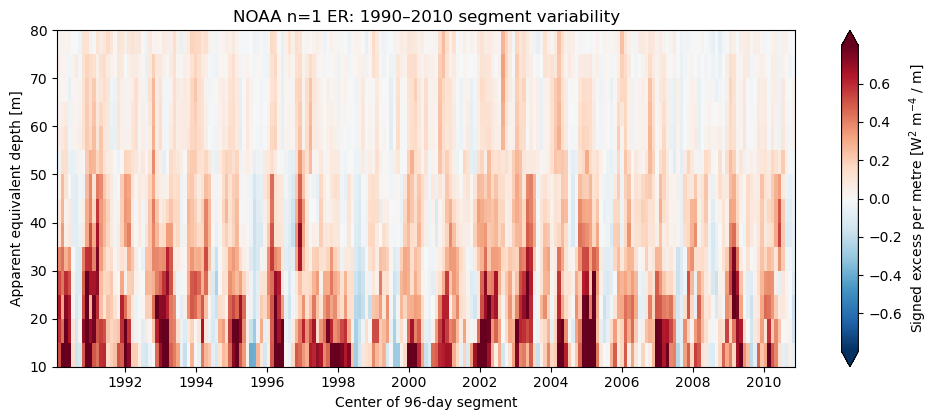

In [8]:
for wave in ["Kelvin", "n1ERW"]:
    values = noaa.signed_excess.sel(wave=wave).transpose("depth", "segment").values / 5
    limit = float(np.quantile(abs(values), .98))
    if limit <= 0:
        raise ValueError(f"No signed spectral variability for {wave}")
    fig, ax = plt.subplots(figsize=(10, 4.3))
    dates = pd.to_datetime(noaa.segment_start.values) + pd.Timedelta(days=47.5)
    image = ax.pcolormesh(dates, noaa.depth, values, shading="nearest", cmap="RdBu_r",
                          norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit))
    fig.colorbar(image, ax=ax, label="Signed excess per metre [W$^2$ m$^{-4}$ / m]", extend="both")
    ax.set(ylim=(10, 80), xlabel="Center of 96-day segment", ylabel="Apparent equivalent depth [m]",
           title=f"NOAA {LABELS[wave]}: 1990–2010 segment variability")
    fig.tight_layout()
    plt.show()


## Interpretation

In NOAA, Kelvin and n=1 ER have broadly similar, shallow-weighted distributions
within 10–80 m: about **57% and 53%** of their mean positive segment excess lies
in 10–30 m. The corresponding model-median shares are 62%/53% in Historical and
60%/54% in AMIP (Kelvin/ER). These normalized shapes conceal substantial
strength differences.

NOAA's integrated **signed** Kelvin excess is 12.25 W² m⁻⁴, compared with model
medians of 5.45 (Historical) and 3.54 (AMIP). For ER the values are 10.07 in NOAA
and 12.59/13.46 in the two model ensembles. These describe the selected record,
latitude-power diagnostic, wave boxes and 10–80 m range; they are not formal
significance statements.

The estimates are apparent, resting-background, **power-weighted** depth
distributions. The background is estimated from the same record, positive
clipping has a noise contribution, wave boxes have different spectral areas,
and ER has poor depth discrimination at 96 days. Use signed and pooled spectral
excess alongside the segment-positive profiles. Similar Kelvin/ER shapes do
not establish identical physical depth distributions. The shared-depth control
also shows that a fine peak/width difference need not imply different true depths.

Keeping segments reveals intermittency. Averaging *signed* segment excess gives
exactly the depth-band integral of the averaged WK spectrum. Longer segments
would be a useful resolution sensitivity test, with a tradeoff in time
localization. Intrinsic depths would also require accounting for mean-flow
Doppler shifts. No standalone figures are written by this notebook.
